# 7. Probability calibration, PR curves and cost-sensitive thresholds (validation only)

A fixed 0.5 cut-off is arbitrary for imbalanced labels. Two principled alternatives:

1. **F1-optimal per-label threshold**, tuned on `val` and then frozen for `test`.
2. **Cost-optimal (Bayes) threshold**: if a missed fallacy costs $C_{FN}$ and a false alarm
   costs $C_{FP}$, predicting positive is optimal when
   $p\,C_{FN} > (1-p)\,C_{FP} \iff p > \dfrac{C_{FP}}{C_{FP}+C_{FN}} = \dfrac{1}{1+r}$,
   with $r = C_{FN}/C_{FP}$. This is only valid if $p$ is **calibrated**, so we check calibration
   first.

The best model (Linear SVM) outputs margins, not probabilities. We wrap it in
`CalibratedClassifierCV(method="sigmoid", cv=5)`, which fits Platt scaling on internal folds
**of the training split**, so validation stays clean for threshold tuning.

In [1]:
import sys, json, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.multiclass import OneVsRestClassifier
from sklearn.svm import LinearSVC
from sklearn.metrics import precision_recall_curve, brier_score_loss, average_precision_score
from src.config import RESULTS, FIGURES
from src.data import load_dataset, get_splits
from src.features import word_tfidf
from src.models import logreg
from src.evaluate import scores, tune_thresholds, bayes_threshold

df, LABELS = load_dataset()
S = get_splits(df, LABELS)
X_tr, Y_tr, _ = S["train"]; X_va, Y_va, _ = S["val"]; del S["test"]
sel = json.loads((RESULTS / "selection.json").read_text())
vec = word_tfidf(ngram_range=(1, 2)); A = vec.fit_transform(X_tr); B = vec.transform(X_va)

s = sel["LinearSVM"]; cwt = None if s["class_weight"] == "None" else "balanced"
cal_svm = OneVsRestClassifier(CalibratedClassifierCV(
    LinearSVC(C=s["C"], class_weight=cwt, max_iter=20000), method="sigmoid", cv=5)).fit(A, Y_tr)
s1 = sel["LR-L1"]
l1 = logreg("l1", s1["C"], None if s1["class_weight"] == "None" else "balanced").fit(A, Y_tr)
P = {"Calibrated LinearSVM": cal_svm.predict_proba(B), "LR-L1 (raw probabilities)": l1.predict_proba(B)}

## 7.1 Reliability diagrams
Pooled over all 16 labels (each argument-label pair is one forecast). A calibrated model
lies on the diagonal. The Brier score is the mean squared error of the probabilities.

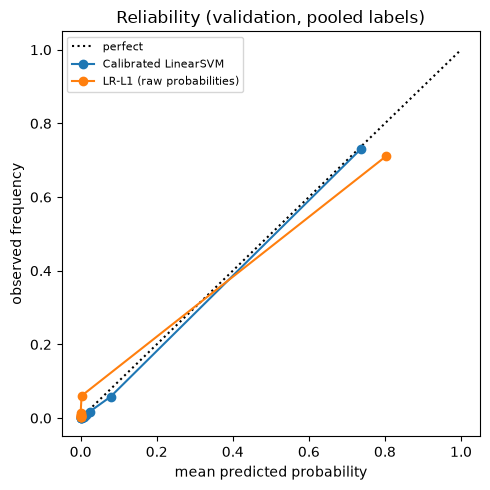

,model,brier
0,Calibrated LinearSVM,0.0207
1,LR-L1 (raw probabilities),0.0272


In [2]:
fig, ax = plt.subplots(figsize=(5, 5)); ax.plot([0, 1], [0, 1], "k:", label="perfect")
cal_rows = []
for name, p in P.items():
    fr, mp = calibration_curve(Y_va.ravel(), p.ravel(), n_bins=10, strategy="quantile")
    ax.plot(mp, fr, marker="o", label=name)
    cal_rows.append({"model": name, "brier": brier_score_loss(Y_va.ravel(), p.ravel()),
                     "curve": list(zip(mp.tolist(), fr.tolist()))})
ax.set_xlabel("mean predicted probability"); ax.set_ylabel("observed frequency")
ax.legend(fontsize=8); ax.set_title("Reliability (validation, pooled labels)")
plt.tight_layout(); plt.savefig(FIGURES / "reliability_val.png", dpi=150); plt.show()
pd.DataFrame(cal_rows)[["model", "brier"]].round(4)

The selected Lasso model uses a very weak penalty (C = 1000) and balanced class weights, and
its probabilities are pushed to the extremes: in the top bin it predicts ≈0.80 while only
≈0.71 of those pairs are positive, i.e. it is **over-confident** (higher Brier score). Its raw
probabilities are therefore not safe to plug into the Bayes threshold formula. The calibrated SVM is used for all thresholding
below and for the threshold tool on the website.

## 7.2 Threshold choice on validation

In [3]:
p = P["Calibrated LinearSVM"]
th_f1 = tune_thresholds(Y_va, p)
rows = []
for name, pred in {"0.5 everywhere": (p >= 0.5).astype(int),
                   "F1-tuned per label (val)": (p >= th_f1).astype(int)}.items():
    rows.append({"rule": name, **{k: v for k, v in scores(Y_va, pred, p).items()
                                  if k in ("macro_f1", "micro_f1", "micro_precision", "micro_recall")}})
print("NOTE: the F1-tuned row is optimistic here because it is tuned and scored on the same data;")
print("its honest estimate is the test-set number in notebook 08.")
pd.DataFrame(rows).round(4)

NOTE: the F1-tuned row is optimistic here because it is tuned and scored on the same data;
its honest estimate is the test-set number in notebook 08.


,rule,micro_f1,macro_f1,micro_precision,micro_recall
0,0.5 everywhere,0.8322,0.8213,0.8640,0.8026
1,F1-tuned per label (val),0.8407,0.8374,0.8489,0.8328


In [4]:
pd.DataFrame({"label": LABELS, "val support": Y_va.sum(0), "F1-optimal threshold": th_f1}).round(2)

,label,val support,F1-optimal threshold
0,Slippery Slope,490,0.56
1,Appeal to Authority,279,0.51
2,Bandwagon / Popularity,262,0.46
3,Hasty Generalization,213,0.40
4,False Cause / Causality,211,0.36
5,Appeal to Emotion,207,0.28
6,Composition,151,0.39
7,False Dilemma,139,0.25
8,Ad Hominem,129,0.46
9,Equivocation,81,0.28


Thresholds for the four rarest labels are estimated from 5–19 validation positives, so they are
noisy (e.g. 0.06 for Denying the Antecedent from 5 positives). A more stable alternative would
be to shrink rare-label thresholds towards a shared value; we keep the simple rule and judge it
on the untouched test split.

## 7.3 Precision–recall curves and cost curves for three representative labels
One frequent (Slippery Slope), one mid-frequency (Ad Hominem), one rare (Red Herring).

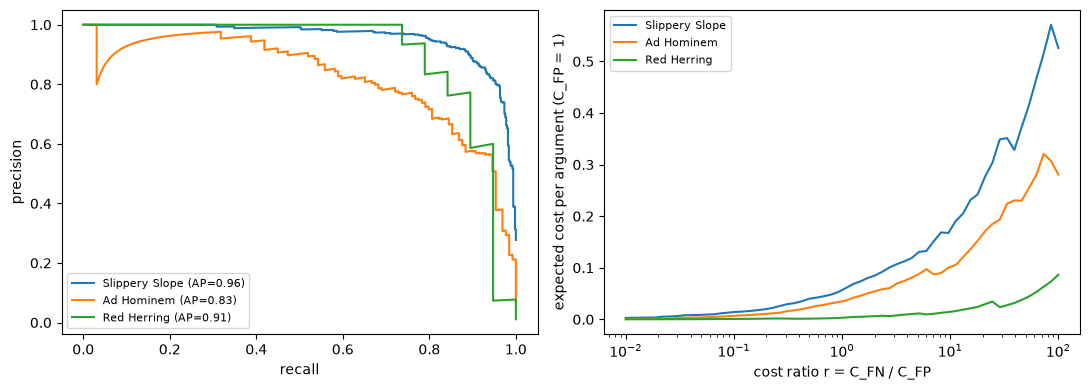

In [5]:
show = ["Slippery Slope", "Ad Hominem", "Red Herring"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for lab in show:
    k = LABELS.index(lab)
    pr, rc, _ = precision_recall_curve(Y_va[:, k], p[:, k])
    axes[0].plot(rc, pr, label=f"{lab} (AP={average_precision_score(Y_va[:, k], p[:, k]):.2f})")
    ratios = np.logspace(-2, 2, 60); costs = []
    for r in ratios:
        t = bayes_threshold(1.0, r); yhat = p[:, k] >= t
        fp = ((yhat == 1) & (Y_va[:, k] == 0)).sum(); fn = ((yhat == 0) & (Y_va[:, k] == 1)).sum()
        costs.append((fp * 1.0 + fn * r) / len(p))
    axes[1].plot(ratios, costs, label=lab)
axes[0].set_xlabel("recall"); axes[0].set_ylabel("precision"); axes[0].legend(fontsize=8)
axes[1].set_xscale("log"); axes[1].set_xlabel("cost ratio r = C_FN / C_FP")
axes[1].set_ylabel("expected cost per argument (C_FP = 1)"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIGURES / "pr_and_cost_val.png", dpi=150); plt.show()

In [6]:
sel["thresholds"] = {"model": "Calibrated LinearSVM", "f1_tuned_on_val": dict(zip(LABELS, th_f1.round(3).tolist()))}
sel["calibration_val"] = [{k: v for k, v in r.items() if k != "curve"} for r in cal_rows]
(RESULTS / "selection.json").write_text(json.dumps(sel, indent=2, default=float)); print("saved")

saved
